In [1]:
import pandas as pd
import numpy as np

import torch
import shap
from botorch.models import SingleTaskGP
from botorch.acquisition import qUpperConfidenceBound
from botorch.optim import optimize_acqf_discrete_local_search
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood

from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 300

In [2]:
def data_convert(df:pd.DataFrame):
    target_cols =['Nluc template', 'Mg(OAc)2', 'NTPs', 'cap2','HEPES-KOH','pyrophosphatase', 'capped mRNA µg/µL']
    df = df[df['Capping efficiency'] != -1]
    df = df[target_cols]
    col_convert = {'Nluc template':'x0','Mg(OAc)2':'x1','NTPs':'x2','cap2':'x3','HEPES-KOH':'x4','pyrophosphatase':'x5','capped mRNA µg/µL':'y'}
    df = df.rename(columns=col_convert)
    return df

In [3]:
raw_data_round2 = pd.read_csv(
    "../data/new_conditions/round2/round2_wet_result.csv",
    index_col=0,
).T
raw_data_round1 = pd.read_csv(
    "../data/new_conditions/round1/round1_wet_result.csv",
    index_col=0,
).T
raw_data_init = pd.read_csv(
    "../data/new_conditions/round_init_exp2.csv",
    index_col=0,
).T
# raw_data  = raw_data.apply(pd.to_numeric, errors='coerce') # convert dtype from object to float
round2 = data_convert(raw_data_round2)
round1 = data_convert(raw_data_round1)
init = data_convert(raw_data_init)

In [4]:
data = pd.concat([init,round1, round2], axis=0)

/tmp/ipykernel_2574887/1402987490.py:21: InputDataWarning: The model inputs are of type torch.float32. It is strongly recommended to use double precision in BoTorch, as this improves both precision and stability and can help avoid numerical errors. See https://github.com/pytorch/botorch/discussions/1444
  gp = SingleTaskGP(X, Y)


  0%|          | 0/45 [00:00<?, ?it/s]

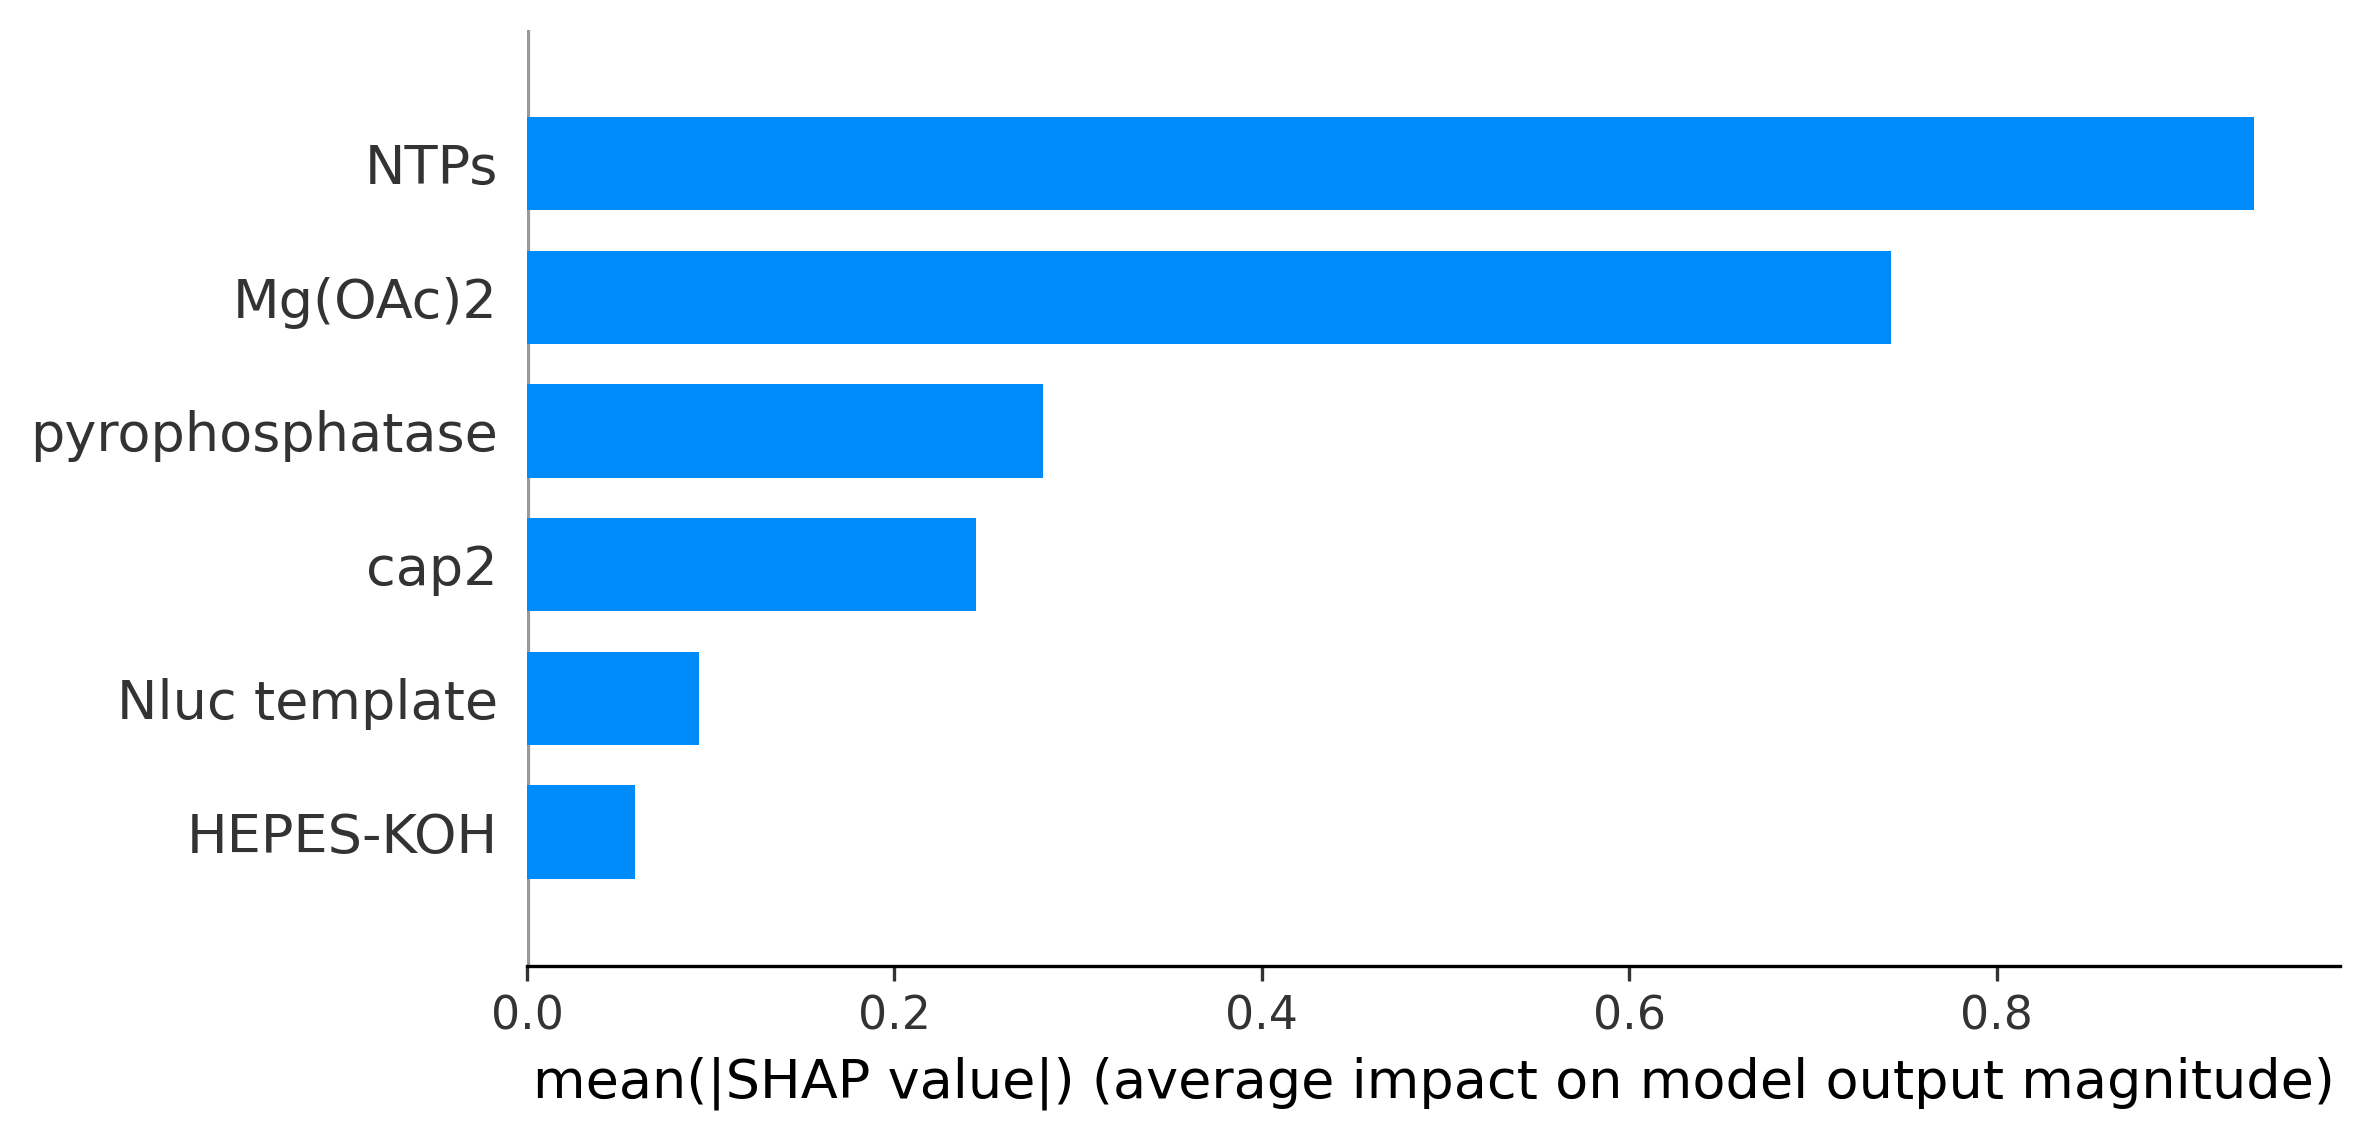

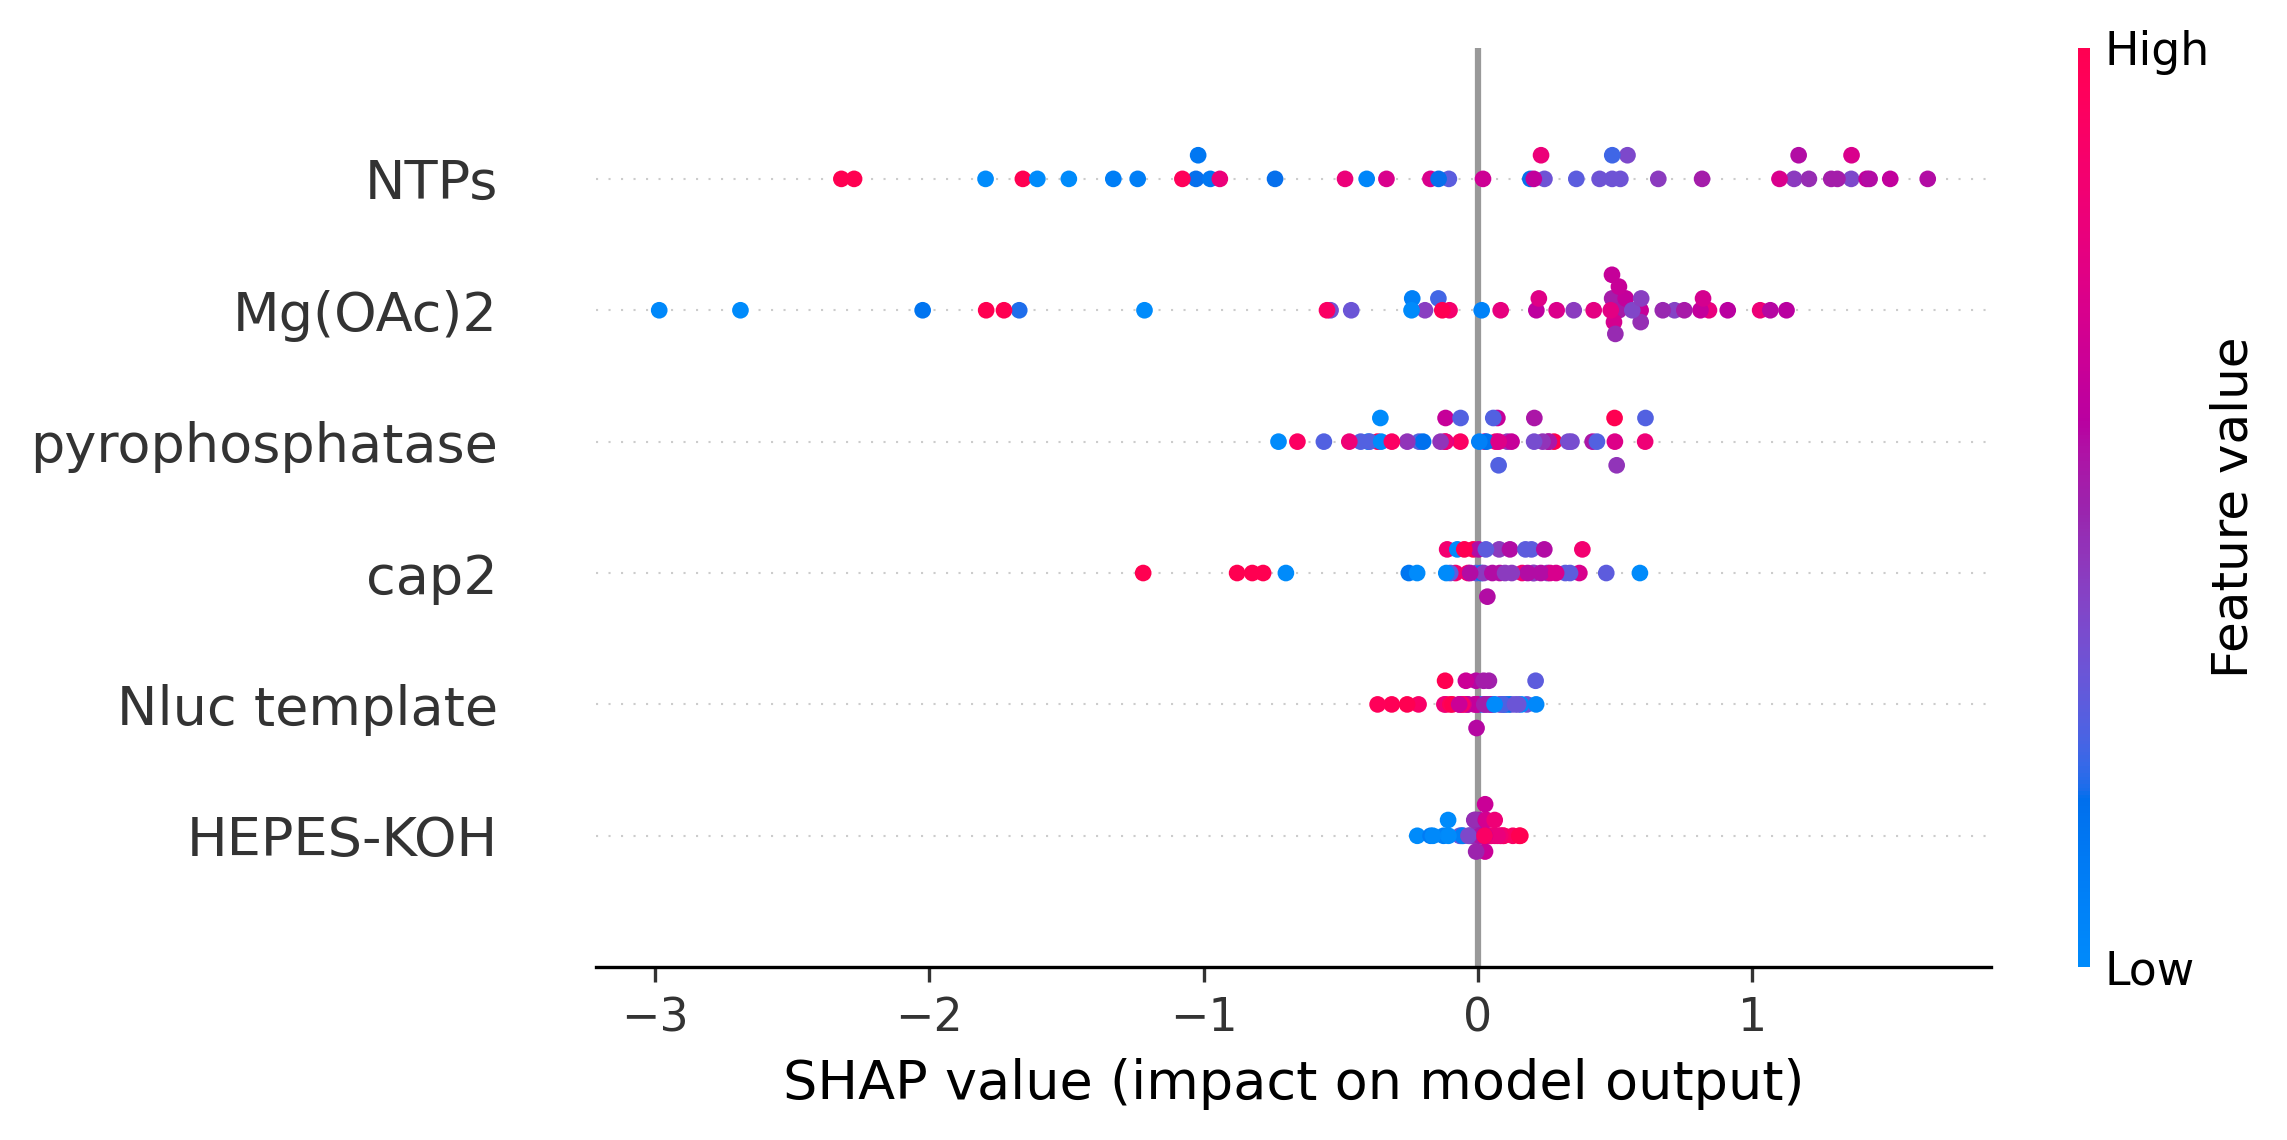

In [5]:
def run_shap(data:pd.DataFrame):
    mmscaler = MinMaxScaler()
    norm_x = mmscaler.fit_transform(data.iloc[:,:-1])
    norm_x_df = pd.DataFrame(norm_x)
    y = data.iloc[:,-1].values
    norm_x_df.insert(len(data.columns)-1,'y',-y)
    norm_x_df.columns = data.columns
    norm_x_df
    #norm_x_df.to_csv('./data/round1_normed.csv')
    #norm_data = pd.read_csv("./data/round1_normed.csv", encoding="shift_jis",index_col=0)
    num_x = norm_x_df.shape[1]-1
   
    # 標準化済みのcsvデータ（既知の実験データ）を読み込む
    #norm_data = pd.read_csv("./data/round1_normed.csv", encoding="shift_jis",index_col=0)
    norm_data_x = norm_x_df.iloc[:,0:num_x]        #全行のxを読み込む
    norm_data_y = norm_x_df.iloc[:,num_x:num_x+1]  #全行のyを読み込む

    X = torch.Tensor(norm_data_x.values)
    Y = -torch.Tensor(norm_data_y.values)

    gp = SingleTaskGP(X, Y)
    mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
    fit_gpytorch_mll(mll)

    def model_predict(X_numpy):
        X_tensor = torch.tensor(X_numpy)
        with torch.no_grad():
            posterior = gp.posterior(X_tensor)
            mean_prediction = posterior.mean.detach().numpy()
        return mean_prediction

    explainer = shap.KernelExplainer(model_predict, X.numpy())
    shap_values = explainer.shap_values(X.numpy())
    shap_values = np.squeeze(shap_values)
    return shap_values, X

shap_values, train_X = run_shap(data)
shap.summary_plot(shap_values, train_X.numpy(), show=False, plot_type="bar", feature_names=['Nluc template', 'Mg(OAc)2', 'NTPs', 'cap2','HEPES-KOH','pyrophosphatase'])
plt.savefig('../figures/shap_bar.png', bbox_inches='tight')
plt.show()
shap.summary_plot(shap_values, train_X.numpy(), show=False, feature_names=['Nluc template', 'Mg(OAc)2', 'NTPs', 'cap2','HEPES-KOH','pyrophosphatase'])
plt.savefig('../figures/shap_beeswarm.png', bbox_inches='tight')
plt.show()
